ECE 3715 Mini Project 2

Team Members: Jovanni Munoz, Ryan Mascola, Andy Nguyen, Miguel Guardado

In [3]:
SEED = 629064958 # drawn 2026-10-19, do not change
rng = np.random.default_rng(SEED)

#Each step in the project has its own independent random generator
rng_step = [rng.spawn(1)[0] for _ in range(8)]

In [4]:
#Import libraries and functions to use throughout the project
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import ndtr, ndtri, erfc
from mp2lib import (inv_cdf_exponential, inv_cdf_rayleigh, sample_by_inversion, ks_statistic, q_function)
#Set up the graphs and display the random seed number
plt.rcParams["figure.figsize"] = (12, 4)
np.set_printoptions(precision=6, suppress=True)
print("Seed:", SEED)

Seed: 629064958


Step 1

Uniform on [0,1]: 

CDF: FX(x) = P(X≤x) = $\int_{-∞}^{x} fX(t) \,dt$
     
x < 0: FX(x) = 0
     
0≤x≤1: FX(x) = $\int_{0}^{x} 1 \,dt$ = x - 0 = x
     
x > 1: FX(x) = 1
     
FX(x) = 

{0, x < 0 

x, 0≤x≤1  

1, x > 1}


PDF: fX(x)= 1, 0≤x≤1 and 0, otherwise
     
Thus, fX(x)=1 on [0,1] and 0 otherwise

Support: 0≤x≤1 
<br>
<br>
<br>
<br>
Exponential with rate 1: 

CDF: FX(x) = $\int_{-∞}^{x} fX(t) \,dt$

x < 0: FX(x) = 0

x ≥ 0: FX(x) = $\int_{0}^{x} e^-t \,dt$ = 1 - e^-x

FX(x) = 

{0, x < 0

1 - e^-x, x ≥ 0}


PDF: fX(x)= λe^-λx, x ≥ 0 and 0, x < 0 where λ = 1  

fX(x)= 

{e^-x, x ≥ 0

0, x < 0}

Support: x ≥ 1
<br>
<br>
<br>
<br>
Standard Gaussian:

CDF:
FX(x) = $\int_{-∞}^{x} fX(t) \,dt$

FX(x) = $\int_{-∞}^{x} {e^-[(t^2)/2]}/sqrt(2π) \,dt$

erf(x) = [2/sqrt(π)]$\int_{0}^{x} [e^(-t^2)] \,dt$

FX(x) = 1/2{1+erf[x/sqrt(2)]}, -∞≤x≤∞


PDF:

Mean: μ = 0

Variance: σ^2 = 1

Standard deviation: σ = 1

fX(x)= [1/(σsqrt(2π)]e^-{[(x-μ)^2]/[2σ^2]}

fX(x)= {e^-[(x^2)/2]}/sqrt(2π), -∞≤x≤∞ for x=all real numbers

Support: -∞≤x≤∞
<br>
<br>
<br>
<br>
Rayleigh with scale 1:

CDF:
FX(x) = $\int_{-∞}^{x} fX(t) \,dt$

x < 0: FX(x) = 0

x ≥ 0: FX(x) = $\int_{0}^{x} te^-(t^2/2) \,dt$ = -(e^-(x^2/2) - 1)

FX(x) = 1 - e^-(x^2/2)

FX(x) = 

{0, x < 0

1 - e^-(x^2/2), x ≥ 0}


PDF:
scale: σ = 1

fX(x)= 

x ≥ 0: (x/σ^2)e^-(x^2/2σ^2) = (x/1)e^-(x^2/2)

fX(x)= 

{xe^-(x^2/2), x ≥ 0
 
 0, x < 0}

Support: x ≥ 0

In [5]:
#Generate random samples with random generators
N = 100_000

#Use the random number generator assigned to Step 1
r = rng_step[0]

#Generate samples from each distribution
uniform_samples = r.random(N)
exponential_samples = r.exponential(scale=1.0, size=N)
gaussian_samples = r.standard_normal(N)
rayleigh_samples = r.rayleigh(scale=1.0, size=N)

#display the generated samples from the distributions
print("Number of samples:", N)
print("Uniform samples:", uniform_samples[:5])
print("Exponential samples:", exponential_samples[:5])
print("Gaussian samples:", gaussian_samples[:5])
print("Rayleigh samples:", rayleigh_samples[:5])

Number of samples: 100000
Uniform samples: [0.703895 0.908264 0.187877 0.85006  0.264992]
Exponential samples: [0.178634 0.415777 3.312022 1.290154 0.071872]
Gaussian samples: [ 1.425332 -1.56859   0.162724  0.222734 -0.824475]
Rayleigh samples: [1.721012 2.604502 0.807279 1.435222 1.289736]


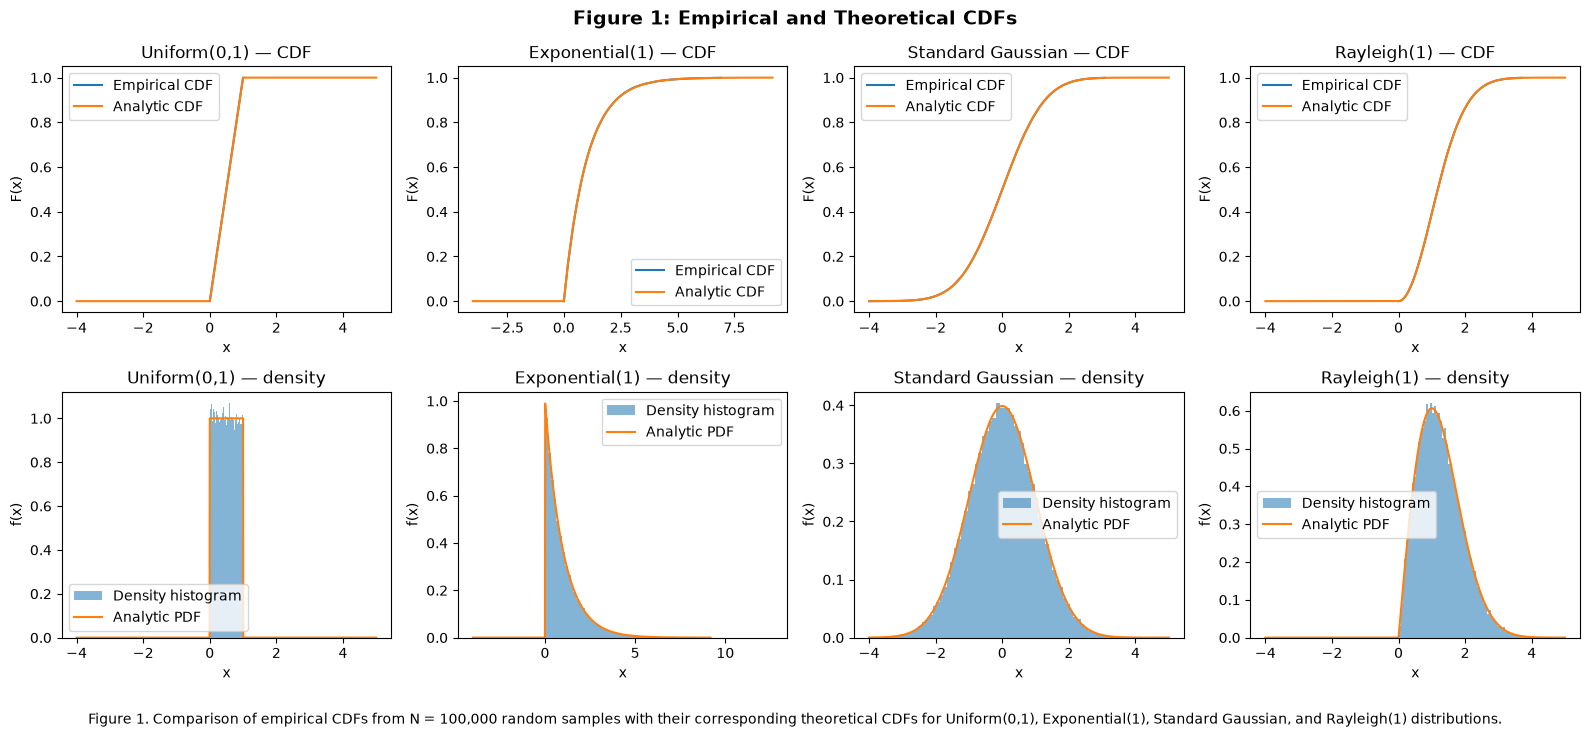

Distribution            KS statistic  95% critical  Below critical?
Uniform(0,1)                0.002126      0.004301             True
Exponential(1)              0.002759      0.004301             True
Standard Gaussian           0.001955      0.004301             True
Rayleigh(1)                 0.002447      0.004301             True


In [9]:
#Define the theoretical CDFs and PDFs to be compared with simulated distributions generated from random samples
#cdfs
def uniform_cdf(x):
    return np.clip(x, 0, 1)
def exponential_cdf(x):
    return np.where(x < 0, 0.0, -np.expm1(-x))
def gaussian_cdf(x):
    return ndtr(x)
def rayleigh_cdf(x):
    return np.where(x < 0, 0.0, -np.expm1(-x**2 / 2))
#pdfs
def uniform_pdf(x):
    return np.where((x >= 0) & (x <= 1), 1.0, 0.0)
def exponential_pdf(x):
    return np.where(x >= 0, np.exp(-x), 0.0)
def gaussian_pdf(x):
    return np.exp(-x**2 / 2) / np.sqrt(2 * np.pi)
def rayleigh_pdf(x):
    return np.where(x >= 0, x * np.exp(-x**2 / 2), 0.0)

#Organize the random samples
samples = {"Uniform(0,1)": uniform_samples, 
           "Exponential(1)": exponential_samples, 
           "Standard Gaussian": gaussian_samples, 
           "Rayleigh(1)": rayleigh_samples}

#Organize the theoretical CDFs
cdfs = {"Uniform(0,1)": uniform_cdf,
        "Exponential(1)": exponential_cdf,
        "Standard Gaussian": gaussian_cdf,
        "Rayleigh(1)": rayleigh_cdf}

#Organize the theoretical PDFs
pdfs = {"Uniform(0,1)": uniform_pdf,
        "Exponential(1)": exponential_pdf,
        "Standard Gaussian": gaussian_pdf,
        "Rayleigh(1)": rayleigh_pdf}

#Plots of the empirical CDFs against the analytic CDFs for the different distributions
critical = 1.36 / np.sqrt(N)
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
ks_rows = []
for j, (name, x) in enumerate(samples.items()):
    xs = np.sort(x)
    ecdf = np.arange(1, N+1) / N
    grid = np.linspace(min(-4, x.min()), max(5, np.quantile(x, .9999)), 1200)
    axes[0, j].plot(xs[::100], ecdf[::100], label="Empirical CDF")
    axes[0, j].plot(grid, cdfs[name](grid), label="Analytic CDF")
    axes[0, j].set(title=name + " — CDF", xlabel="x", ylabel="F(x)")
    axes[0, j].legend()

    #Plots of the normalized histogram against the analytic PDFs for the different distributions
    axes[1, j].hist(x, bins=80, density=True, alpha=.55, label="Density histogram")
    axes[1, j].plot(grid, pdfs[name](grid), label="Analytic PDF")
    axes[1, j].set(title=name + " — density", xlabel="x", ylabel="f(x)")
    axes[1, j].legend()

    """Compare the KS statistic which provides the max gap between empirical and analytic CDFs 
    for each distribution against the 95% critical value at sample size 100000 which is .0043"""
    ks = ks_statistic(x, cdfs[name])
    ks_rows.append((name, ks, critical, ks < critical))

#Add the overall figure title
fig.suptitle("Figure 1: Empirical and Theoretical CDFs", fontsize=14, fontweight="bold")

#Add a caption underneath the grid
fig.text(0.5, -0.04, "Figure 1. Comparison of empirical CDFs from N = 100,000 "
"random samples with their corresponding theoretical CDFs "
"for Uniform(0,1), Exponential(1), Standard Gaussian, "
"and Rayleigh(1) distributions.", ha="center", fontsize=10, wrap=True)

plt.tight_layout()
plt.show()
print(f"{'Distribution':22s} {'KS statistic':>13s} {'95% critical':>13s} {'Below critical?':>16s}")
for row in ks_rows:
    print(f"{row[0]:22s} {row[1]:13.6f} {row[2]:13.6f} {str(row[3]):>16s}")

Figure 1 compares empirical cumulative distribution functions or CDFs for 100,000 simulated samples to their corresponding theoretical CDFs obtained analytically. The distribution functions include Uniform(0,1), Exponential(1), Standard Gaussian, and Rayleigh(1). As one can see by the graph, the empirical CDFs closely follow the theoretical CDFs, which means that the generated random samples match the expected probability distributions. The Uniform distribution shows that as the CDF increases linearly from 0 to 1 over the interval [0,1]. The Exponential distribution shows that a rapid increase occurs near 0 and gradually approaches 1 as x increases. The Standard Gaussian has an S shape CDF centered at 0 and a symmetric distribution. The Rayleigh starts at 0 and increases to 1 with the majority of probability around positive values. Although the curves may seem similar there are some small differences that are due to the finite number of samples in the empirical curve.

After all, the visual comparison is supported by the Kolmogorov–Smirnov or KS test, which measures the max difference between empirical and theoretical CDFs. Therefore, for N=100,000 samples the 95% critical value for the distributions is .0043. As one can see by the table the Uniform distribution has a KS statistic of around .0021, the Exponential distribution has a KS statistic of around .0028, the Standard Gaussian distribution has a KS statistic of around .002, and the Rayleigh distribution has a KS statistic of around .0024. Thus, since the KS statistics for all the distributions are below the value, it indicates that the difference between theoretical and empirical isn't large enough to reject the distributions. 

For the PDFs, the density histogram show the distribution for a simulated 100,000 random samples against the theoretical probability density functions for Uniform(0,1), Exponential(1), Standard Gaussian, and Rayleigh(1). As one can see by the graph, the Uniform distribution in the density histogram is constant between 0 and 1 and matches the theoretical PDF with a density of 1 throughout the interval, which means that the samples are distributed uniformly. The Exponential distribution has the highest density near 0 and decreases as x increases, which follows the theoretical PDF to show that larger sample values occur less frequently. The Standard Gaussian distribution shows that the histogram forms a bell shaped curve centered at 0 and high density near the mean 0. This matches the theoretical PDF because for both cases the density decreases symmetrically in the positive and negative direction. The Rayleigh distribution histogram shows that at x=0, the density is near 0, and as x increases the distribution also increases to its max and decreases afterward. This matches the theoretical PDF because they are both proportional to x. In conclusion, the small difference in the histogram is due to the random finite number samples.

In [20]:
#Standard Error Calculations
#Organize the existing random samples
distributions = {"Uniform(0,1)": uniform_samples,  "Gaussian": gaussian_samples, "Rayleigh(1)": rayleigh_samples, "Exponential(1)": exponential_samples}
#Print table headings
print(f"{'Distribution':22s} {'CDF Standard Error':>20s} {'PDF Standard Error':>20s}")
#Calculate standard errors for each distribution
for name, x in distributions.items():
    N = len(x)
    #CDF Standard Error
    #Sort the samples
    xs = np.sort(x)
    #Calculate empirical CDF
    ecdf = np.arange(1, N + 1) / N
    #Calculate CDF standard error at each point
    cdf_se = np.sqrt(ecdf * (1 - ecdf) / N)
    #Report maximum CDF standard error
    max_cdf_se = np.max(cdf_se)
    
    #PDF Standard Error
    #Calculate histogram counts and bin edges
    counts, edges = np.histogram(x, bins=80)
    #Calculate bin widths
    widths = np.diff(edges)
    #Calculate probability in each bin
    p = counts / N
    #Calculate PDF standard error for each bin
    pdf_se = np.sqrt(p * (1 - p) / N) / widths
    #Report maximum PDF standard error
    max_pdf_se = np.max(pdf_se)
    #Print results
    print(f"{name:22s} {max_cdf_se:20.6f} {max_pdf_se:20.6f}")

Distribution             CDF Standard Error   PDF Standard Error
Uniform(0,1)                       0.001581             0.029035
Gaussian                           0.001581             0.006041
Rayleigh(1)                        0.001581             0.010033
Exponential(1)                     0.001581             0.007084


Closed Form formulas:

Exponential:

Mean:

1/λ = 1/1 = 1
<br>
<br>
Median:

ln2/λ = .6931
<br>
<br>
Variance:

1/λ^2 = 1/1^2 = 1
<br>
<br>
<br>
<br>
Rayleigh:

Mean:

σsqrt(π/2) = 1sqrt(π/2) = 1.2533

Median:

σsqrt(2ln2) = 1sqrt(2ln2) = 1.1774

Variance:

[(4-π)/2]σ^2 = [(4-π)/2]1^2 = .4292

In [11]:
#Compute Sample mean, median, and variance to compare with for exponential and Rayleigh to compare with the closed form
print("Distribution      sample mean   theory mean   sample median   theory median   sample variance   theory variance")
exp_x = samples["Exponential(1)"]
ray_x = samples["Rayleigh(1)"]
moment_rows = [("Exponential", exp_x.mean(), 1.0, np.median(exp_x), np.log(2), exp_x.var(), 1.0), ("Rayleigh", ray_x.mean(), np.sqrt(np.pi/2), np.median(ray_x), np.sqrt(2*np.log(2)), ray_x.var(), 2-np.pi/2),]
for row in moment_rows:
    print(f"{row[0]:13s} {row[1]:12.6f} {row[2]:12.6f} {row[3]:14.6f} {row[4]:14.6f} {row[5]:16.6f} {row[6]:15.6f}")

Distribution      sample mean   theory mean   sample median   theory median   sample variance   theory variance
Exponential       0.998810     1.000000       0.695466       0.693147         0.993239        1.000000
Rayleigh          1.252496     1.253314       1.176152       1.177410         0.428802        0.429204


The closed form values are the theoretical values for the distributions and the sample values were calculated using the 100,000 random samples, which is why the results are slightly different. Thus, we can see that by increasing the samples, the values will approach their theoretical values.

The exponential distribution is right skewed in the density histogram, which has allowed the mean to be larger than the median and is why there is a factor of 1.44. The Gaussian mean and median coincide because in the density histogram one may see that it is symmetric about 0, which has allowed for an even distribution on both sides.

Step 5

Mean and Variance of the Sum of N Uniform

The mean of one Uniform(0,1) random variable is:

E[X_i] = 1/2

The variance of one Uniform(0,1) random variable is:

Var(X_i) = 1/12

The sum of (N) independent Uniform(0,1) random variables is:

S_N = X_1 + X_2 + ... + X_N

Using independence, the mean and variance of the sum are:

E[S_N] = N/2

Var(S_N) = N/12
<br>
<br>
<br>
<br>
The mean of a sum of N Pareto variables

E[X] = α / (α-1) = 3

E[S_N] = 3N


In [16]:
#Standardize each sum to zero mean and unit variance while reporting KS statistic against standard normal CDF
r = rng_step[4]
M = 200_000
uniform_ns = [1, 2, 3, 5, 10, 30]

#Print the theoretical mean and variance of the uniform sums
print("Theoretical mean and variance of uniform sums:")
print("N       Mean       Variance")
for n in uniform_ns:
    mean_sum = n / 2
    variance_sum = n / 12
    print(f"{n:<7} {mean_sum:<10.4f} {variance_sum:.4f}")

uniform_ks = []
uniform_sums = {}
#Each row contains n independent Uniform(0,1) values
for n in uniform_ns:
    sums = r.random((M, n)).sum(axis=1)
    z = (sums - n/2) / np.sqrt(n/12)
    uniform_sums[n] = z
    uniform_ks.append(ks_statistic(z, ndtr))
uniform_critical = 1.36/np.sqrt(M)
print("Uniform sums compared with Standard Normal CDF")
print("N KS Statistic 95% Critical Value")
for n, d in zip(uniform_ns, uniform_ks):
    print(n, f"{d:.6f}", f"{uniform_critical:.6f}")

#Pareto experiment, which is centered by the finite mean and scale by N^(1/alpha);
#This is the natural heavy-tail scaling, not a variance standardization
#Report KS statistic using Pareto
pareto_ns = [1, 10, 100, 1000]
pareto_ks = []
pareto_zs = {}
alpha = 1.5
for n in pareto_ns:
    vals = r.pareto(alpha, size=(M, n)) + 1
    sums = vals.sum(axis=1)
    z = (sums - n*3.0) / (n**(1/alpha))
    pareto_zs[n] = z
    pareto_ks.append(ks_statistic(z, ndtr))
#Calculate the 95% KS critical value
pareto_critical = 1.36 / np.sqrt(M)

#Print the theoretical mean and KS critical value
print("\nPareto sums: Mean and KS comparison against Standard Normal CDF")
print("N       Mean of Sum       KS Statistic       95% Critical Value")

for n, d in zip(pareto_ns, pareto_ks):
    mean_sum = n * 3.0
    print(f"{n:<7} {mean_sum:<17.4f} {d:<18.6f} {pareto_critical:.6f}")
print("\nPareto centered, heavy-tail-scaled sums vs standard normal:")
for n, d in zip(pareto_ns, pareto_ks):
    print(n, f"{d:.6f}")

Theoretical mean and variance of uniform sums:
N       Mean       Variance
1       0.5000     0.0833
2       1.0000     0.1667
3       1.5000     0.2500
5       2.5000     0.4167
10      5.0000     0.8333
30      15.0000    2.5000
Uniform sums compared with Standard Normal CDF
N KS Statistic 95% Critical Value
1 0.057458 0.003041
2 0.017294 0.003041
3 0.012216 0.003041
5 0.006878 0.003041
10 0.002745 0.003041
30 0.002513 0.003041

Pareto sums: Mean and KS comparison against Standard Normal CDF
N       Mean of Sum       KS Statistic       95% Critical Value
1       3.0000            0.488301           0.003041
10      30.0000           0.447796           0.003041
100     300.0000          0.429219           0.003041
1000    3000.0000         0.418122           0.003041

Pareto centered, heavy-tail-scaled sums vs standard normal:
1 0.488301
10 0.447796
100 0.429219
1000 0.418122


As one may see that for the uniform case as N increases the sum distribution becomes more Gaussian and fall like 1/sqrt(N). When the KS statistic is greater than .003, the difference from the Gaussian is detectable by around 5%, but when it's below, the test doesn't reject the standard normal model. Thus, when N=2X10^7 samples the 95% critical value is .003, which means that at N=30, the ditribution is still distinguishable from a Gaussian. It is also noticeable that from the Pareto, as N increases the KS statistic decreases to stay in the range of .3 and .45. Thus, the Pareto doesn't converge to the standard Gaussian distribution.

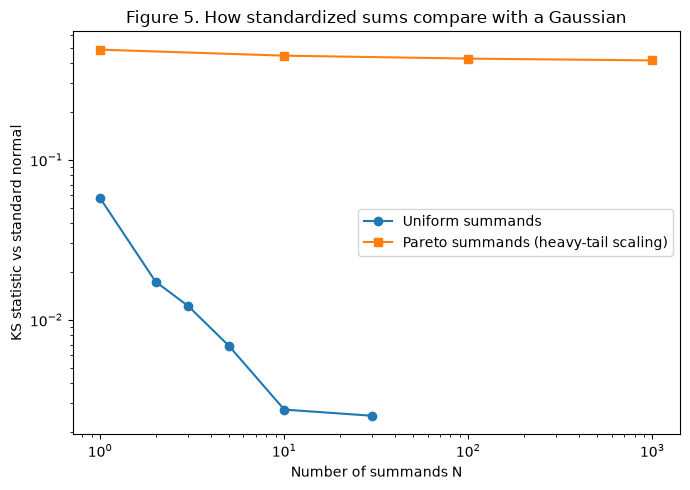

In [17]:
#plot figure 5 KS statistic against N on log-log axes, uniform summands and Pareto 
fig, ax = plt.subplots(figsize=(7, 5))
ax.loglog(uniform_ns, uniform_ks, "o-", label="Uniform summands")
ax.loglog(pareto_ns, pareto_ks, "s-", label="Pareto summands (heavy-tail scaling)")
ax.set(xlabel="Number of summands N", ylabel="KS statistic vs standard normal",
       title="Figure 5. How standardized sums compare with a Gaussian")
ax.legend()
plt.tight_layout()
plt.show()

Figure 5 is comparing standardized sums for Pareto and Uniform distributions to Gaussian and as one can see that as N increases in the Uniform curve, the KS statistic decreases, which indicates that the stadardized sums are getting closer to the standard Gaussian distribution. We can also see that the Pareto curve doesn't show the same convergence toward zero, which indicates that the heavy tailed distribution has infinte variance and so the Gaussian CLT doesn't apply.

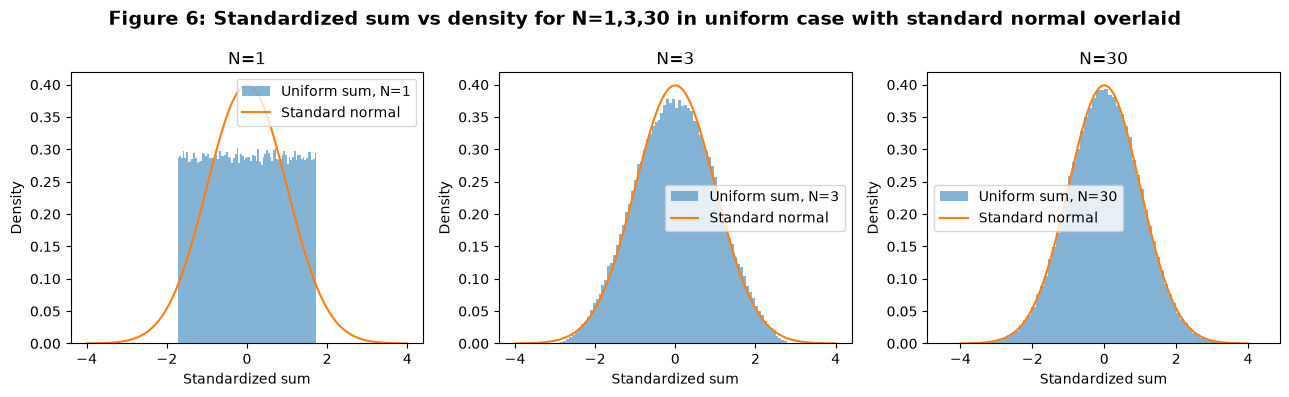

Uniform 95% KS critical value: 0.0030410524493997143


In [19]:
#Plot figure 6 Histograms of standardized sum of N=1,3,30 for uniform case with standard normal overlaid
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
grid = np.linspace(-4, 4, 500)
#Add the overall figure title
fig.suptitle("Figure 6: Standardized sum vs density for N=1,3,30 in uniform case with standard normal overlaid", fontsize=14, fontweight="bold")
for ax, n in zip(axes, [1, 3, 30]):
    ax.hist(uniform_sums[n], bins=80, density=True, alpha=.55, label=f"Uniform sum, N={n}")
    ax.plot(grid, np.exp(-grid**2/2)/np.sqrt(2*np.pi), label="Standard normal")
    ax.set(title=f"N={n}", xlabel="Standardized sum", ylabel="Density")
    ax.legend()
plt.tight_layout()
plt.show()
print("Uniform 95% KS critical value:", uniform_critical)

The Figure 6 shows the standardized sum vs the density as n increases in the uniform case. As expected, as N increases it becomes similar to the standard normal Gaussian distribution. Thus, when N=1, the distribution looks to be Uniform and when N=3, the distribution gets closer to Gaussian. Finally, when N=30, the histogram resembles a standard normal curve. In conclusion, by increasing the number of independent uniform random variables makes the standardized sum look more like Gaussian, which is the predicted behavior by the Central Limit Theorem.

Even at N=30 the distribution is formally distinguishable from a Gaussian, and this is not a failure of the CLT or Central Limit Theorem because CLT states that the standardized sum of independent random variables with finite mean and variance approaches a Gaussian distribution as N increases, but since it doesn't state when the distribution becomes exactly Gaussian for a finite N, it is possible for the sample size of 200,000 to be large enough that the KS test can detect even very small differences between the standardized uniform sums and the standard normal distribution. Thus, there will be a small difference between the KS statistic and the 95% critical value at N=30. The difference between a distribution that is statistically distinguishable from Gaussian and one that is pratically different is that a statistically distinguishable distribution has a measurable difference according to a statistical test and a pratically different distribution has differences large enough to affect the shape or meaningful applications.

The Pareto distribution has a shape parameter of α = 1.5, a finite mean, and an infinite variance because α is less than or equal to 2, which causes the convergence to stall. Thus, the hypothesis of the central limit theorem that the Pareto violates is the hypothesis of finite variance because the Pareto has infinite variance. Therefore, the standardized sums don't converge to a Gaussian distribution and instead after centering by the mean and scaling by N^(-1/α), the sums converge to a non-Gaussian stable distribution with a stability of 1.5. In conclusion, the reason convergence stalls because Pareto produces extremely large values that have a large influence on the sum than the distribution with a finite variance.